# LSTM Practice Implementation

## Configuring MPS

In [239]:
import torch
import torch.nn as nn

#Set the device automatically: Cuda/Mps
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


## Viewing the CSV

In [240]:
import pandas as pd

df = pd.read_csv("example_data.csv")

df.head(5)

,ID,TIMESTAMP,OBJID,UTM_X,UTM_Y,UTM_ANGLE,V,ACC,ACC_LAT,ACC_TAN,CLASS,WIDTH,LENGTH,TRAILER_ID
0,1,0.000000,781,619286.66,5809131.98,4.083985,5.08,1.2648,0.8481,-0.9383,Car,1.8528,4.4024,NaN
1,2,0.033367,781,619286.55,5809131.84,4.080685,5.04,1.3233,0.9102,-0.9606,Car,1.8528,4.4024,NaN
2,3,0.066733,781,619286.44,5809131.70,4.077685,5.01,1.3914,0.9564,-1.0106,Car,1.8528,4.4024,NaN
3,4,0.100100,781,619286.33,5809131.56,4.074785,4.98,1.4524,0.9900,-1.0627,Car,1.8528,4.4024,NaN
4,5,0.133467,781,619286.22,5809131.42,4.071885,4.94,1.5068,1.0110,-1.1174,Car,1.8528,4.4024,NaN


In [241]:
#considering vehicle classes
print(df['CLASS'].value_counts())

CLASS
Car               206642
Pedestrian         26242
Bicycle            12926
Medium Vehicle     12012
Trailer             4002
Bus                 3495
Heavy Vehicle       1412
Motorcycle          1181
Name: count, dtype: int64


## Filtering the Data

In [242]:
#keeping only vehicle classes
vehicle_classes = [
    "Car",
    "Medium Vehicle",
    "Trailer",
    "Bus",
    "Heavy Vehicle",
    "Motorcycle"
]

df = df[df["CLASS"].isin(vehicle_classes)]

In [243]:
#verification
print(df["CLASS"].value_counts())

CLASS
Car               206642
Medium Vehicle     12012
Trailer             4002
Bus                 3495
Heavy Vehicle       1412
Motorcycle          1181
Name: count, dtype: int64


In [244]:
#removal of less the 150 object observations
trajectory_lengths = df.groupby("OBJID").size()
valid_objids = trajectory_lengths[trajectory_lengths >= 150].index
df = df[df["OBJID"].isin(valid_objids)]

## Creating Sliding Windows

In [245]:
vehicle = df[df["OBJID"] == 782]
positions = vehicle[["UTM_X", "UTM_Y"]].values
print(positions.shape)

(511, 2)


In [246]:
#defining input and target (first 60, next 90)
input_positions = positions[:60]
target_positions = positions[60:150]

#verification
print(input_positions.shape, target_positions.shape)

(60, 2) (90, 2)


In [247]:
#making coordinates relative to the starting point
origin = input_positions[0]
input_relative = input_positions - origin
target_relative = target_positions - origin

#verification
print(input_relative[0])
print(target_relative[0])

[0. 0.]
[-1.47 -9.99]


In [248]:
def make_windows(positions, input_length=60, target_length=90, stride=10):
    inputs = []
    targets = []

    total_length = input_length + target_length

    for start in range(0, len(positions) - total_length + 1, stride):
        window = positions[start:start + total_length]

        input_positions = window[:input_length]
        target_positions = window[input_length:]

        origin = input_positions[0]

        input_relative = input_positions - origin
        target_relative = target_positions - origin

        inputs.append(input_relative)
        targets.append(target_relative)

    return inputs, targets

In [249]:
#testing make_windows on vehicle 782
inputs, targets = make_windows(positions)

print(len(inputs))
print(inputs[0].shape)
print(targets[0].shape)

37
(60, 2)
(90, 2)


In [250]:
vehicle_ids = df["OBJID"].unique()

print(len(vehicle_ids))

348


In [251]:
#define train, validate, test split (70/15/15) by objectID so same vehicle isn't used in train and test (cheating)
import numpy as np

np.random.seed(1)

np.random.shuffle(vehicle_ids)

n = len(vehicle_ids)

train_ids = vehicle_ids[:int(0.7 * n)]
val_ids = vehicle_ids[int(0.7 * n):int(0.85 * n)]
test_ids = vehicle_ids[int(0.85 * n):]

#verification
print(len(train_ids))
print(len(val_ids))
print(len(test_ids))

243
52
53


## Making Train, Val and Test Sets

In [252]:
def create_dataset(df, vehicle_ids):
    inputs = []
    targets = []

    for objid in vehicle_ids:
        vehicle = df[df["OBJID"] == objid]
        positions = vehicle[["UTM_X", "UTM_Y"]].values

        vehicle_inputs, vehicle_targets = make_windows(positions)

        inputs.extend(vehicle_inputs)
        targets.extend(vehicle_targets)

    return inputs, targets

In [253]:
# defining each set 
train_inputs, train_targets = create_dataset(df, train_ids)
val_inputs, val_targets = create_dataset(df, val_ids)
test_inputs, test_targets = create_dataset(df, test_ids)

#validation
print("Train:", len(train_inputs))
print("Validation:", len(val_inputs))
print("Test:", len(test_inputs))

Train: 12485
Validation: 2609
Test: 2768


## Converting Data to PyTorch Tensors

In [254]:
train_inputs = torch.tensor(train_inputs, dtype=torch.float32)
train_targets = torch.tensor(train_targets, dtype=torch.float32)

val_inputs = torch.tensor(val_inputs, dtype=torch.float32)
val_targets = torch.tensor(val_targets, dtype=torch.float32)

test_inputs = torch.tensor(test_inputs, dtype=torch.float32)
test_targets = torch.tensor(test_targets, dtype=torch.float32)

In [255]:
#verification
print(train_inputs.shape)
print(train_targets.shape)
print(val_inputs.shape)
print(val_targets.shape)
print(test_inputs.shape)
print(test_targets.shape)

torch.Size([12485, 60, 2])
torch.Size([12485, 90, 2])
torch.Size([2609, 60, 2])
torch.Size([2609, 90, 2])
torch.Size([2768, 60, 2])
torch.Size([2768, 90, 2])


## Making PyTorch Dataset

In [256]:
#the dataset stores data examples and their corresponding labels
#and gives us one example at a time
from torch.utils.data import Dataset

class TrajectoryDataset(Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, index):
        return self.inputs[index], self.targets[index]

In [257]:
train_dataset = TrajectoryDataset(train_inputs, train_targets)
val_dataset = TrajectoryDataset(val_inputs, val_targets)
test_dataset = TrajectoryDataset(test_inputs, test_targets)

In [258]:
x, y = train_dataset[0]

print(x.shape)
print(y.shape)

torch.Size([60, 2])
torch.Size([90, 2])


## Making Pytorch Dataloader

In [259]:
# DataLoader groups examples into batches
from torch.utils.data import DataLoader

# Only shuffle the training data so the model get examples
# in a different order each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

#iter(train_loader) creates an iterator through the batches
#next(...) gets the next batch from that iterator
#shuffle=True means the examples in this batch will be
#different each time this line runs
x_batch, y_batch = next(iter(train_loader))

# Verification:
print(x_batch.shape)
print(y_batch.shape)

torch.Size([32, 60, 2])
torch.Size([32, 90, 2])


## Defining LSTM Architecture

In [260]:
class TrajectoryLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=2,
            hidden_size=64, #sensible moderate hyperparameter, however, may change during validation
            batch_first=True
        )

        self.linear = nn.Linear(64, 180)

        #this direct-prediction architecture is a simplified starting point, sequence to sequence may be better later
        #direct prediction: predict all 90 future locations
        #sequence-to-sequence: predict future locations one at a time
    def forward(self, x):
        #pass the input through the LSTM
        output, (hidden, cell) = self.lstm(x)
    
        #remove the unnecessary layer dimension
        hidden = hidden.squeeze(0)
    
        #produce 180 numbers
        output = self.linear(hidden)
    
        #turn those 180 numbers into coordinates
        output = output.reshape(-1, 90, 2)
    
        return output
        
        #If x = (32, 60, 2), then output = (32, 60, 64), hidden = (1, 32, 64), cell   = (1, 32, 64)
        # output — the hidden state at every one of the 60 input timesteps
        # hidden — the final hidden state
        # cell — the final cell state


## Running Model

In [261]:
model = TrajectoryLSTM()

## Defining Loss Function (MSE)

In [262]:
loss_fn = nn.MSELoss()

## Optimiser

In [263]:
#utilising PyTorch's Adam Optimiser 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Completing One Full Training Cycle on a Batch

In [264]:
# # reset optimiser gradient
# optimizer.zero_grad()

# # make new prediction using batch
# prediction = model(x_batch)

# #calculate loss
# loss = loss_fn(prediction, y_batch)

# #calculate gradients for optimisation step
# loss.backward()

# #update weights accordingly 
# optimizer.step()

## Full Epoch

In [265]:
# model.train()

# total_loss = 0

# for x_batch, y_batch in train_loader:

#     optimizer.zero_grad()

#     prediction = model(x_batch)

#     loss = loss_fn(prediction, y_batch)

#     loss.backward()

#     optimizer.step()

#     total_loss += loss.item()

# average_loss = total_loss / len(train_loader)

# print("Training loss:", average_loss)

## Multiple Epochs

In [266]:
num_epochs = 100
losses = []

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for x_batch, y_batch in train_loader:

        optimizer.zero_grad()

        prediction = model(x_batch)

        loss = loss_fn(prediction, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    
    losses.append(average_loss)

    print("Epoch:", epoch + 1, "Training loss:", average_loss)

Epoch: 1 Training loss: 57.38326220256288
Epoch: 2 Training loss: 13.777975729359385
Epoch: 3 Training loss: 6.94921272916867
Epoch: 4 Training loss: 5.152635846906306
Epoch: 5 Training loss: 4.509779275225862
Epoch: 6 Training loss: 3.8437130826208596
Epoch: 7 Training loss: 3.3421846789777128
Epoch: 8 Training loss: 2.956560767520114
Epoch: 9 Training loss: 2.621400944717095
Epoch: 10 Training loss: 2.5733072285152154
Epoch: 11 Training loss: 2.6107449694667633
Epoch: 12 Training loss: 2.2735206051860626
Epoch: 13 Training loss: 2.1396864968187668
Epoch: 14 Training loss: 2.092404363100486
Epoch: 15 Training loss: 2.001690661282186
Epoch: 16 Training loss: 1.9401241204012996
Epoch: 17 Training loss: 1.9313334618383051
Epoch: 18 Training loss: 1.796400447788141
Epoch: 19 Training loss: 1.8777387779387062
Epoch: 20 Training loss: 1.818234951447343
Epoch: 21 Training loss: 1.6627439016576313
Epoch: 22 Training loss: 1.56531084589946
Epoch: 23 Training loss: 1.5880190153865863
Epoch: 24 

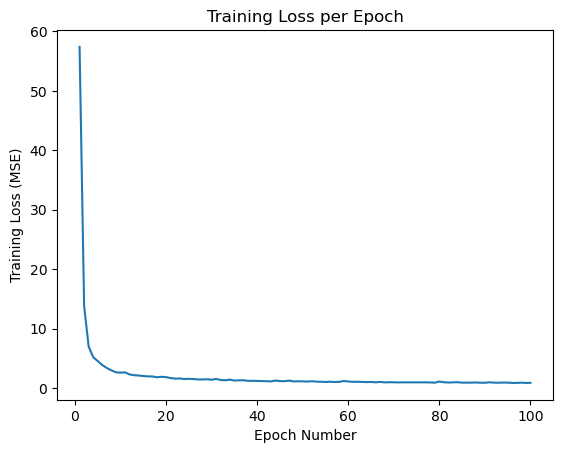

In [267]:
import matplotlib.pyplot as plt
plt.plot(range(1, num_epochs + 1), losses)

plt.xlabel("Epoch Number")
plt.ylabel("Training Loss (MSE)")
plt.title("Training Loss per Epoch")

plt.show()